## Pytorch Fundamentals

In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print(torch.__version__)

2.8.0+cu126


## Introduction to tensors

In [ ]:
# Scalar
scalar = torch.tensor(7)
scalar

tensor(7)

In [ ]:
scalar.ndim

0

In [ ]:
scalar.item()

7

In [ ]:
vector = torch.tensor([7,7])
vector
# ndim shows the number of dimensions

tensor([7, 7])

In [ ]:
vector.shape

torch.Size([2])

In [ ]:
MATRIX = torch.tensor([[7,8],[9,10]])
MATRIX
MATRIX.ndim
MATRIX.shape

torch.Size([2, 2])

In [ ]:
# Tensor
TENSOR = torch.tensor([[[1,2,3],[4,5,6],[7,8,9]]])
TENSOR

tensor([[[1, 2, 3],
         [4, 5, 6],
         [7, 8, 9]]])

In [ ]:
# Random tensors
# Are important because most neural networks learn through start with full of random numbers, look at data, update random numbers, look at data, update random numbers.....
random_tensor = torch.rand(3,4)
random_tensor

tensor([[0.3190, 0.3650, 0.9486, 0.4978],
        [0.4621, 0.6975, 0.3958, 0.6239],
        [0.8751, 0.3463, 0.5741, 0.5639]])

In [ ]:
random_tensor = torch.rand(1, 3, 5)
random_tensor

tensor([[[0.7484, 0.6330, 0.9496, 0.8873, 0.7120],
         [0.8064, 0.9472, 0.7167, 0.5188, 0.9175],
         [0.0381, 0.1731, 0.5972, 0.8192, 0.6986]]])

In [ ]:
# Create a random tensor with similar shape to an image tensor => h, w, rgb
# torch.size(3, 244, 244)

In [ ]:
# Create a tensor with 0
zeros = torch.zeros(size=(3,4))
zeros

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])

In [ ]:
ones = torch.ones(size=(3,4))
ones

tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])

In [ ]:
# Creating a range of tensors
one_to_ten = torch.arange(start=1, end=11, step=1)
one_to_ten
# You can set any start end, ex end=73


tensor([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [ ]:
ten_zeroes = torch.zeros_like(input=one_to_ten)
ten_zeroes

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
# The standard dtype is float32. THis means that the number is stored as as 32 bits.
# The more bits, the more detail but also more time.
# Be careful as this diferent data type for tensors can casue errors.


In [ ]:
float_32_tensor = torch.tensor([3.0, 6.0, 9.0], dtype=None, device=None, requires_grad=False)
float_32_tensor

tensor([3., 6., 9.])

In [ ]:
float_16_tensor = float_32_tensor.type(torch.float16)
float_16_tensor * float_32_tensor
# Although multiplying them works, it doesn't always work, especeically with many long calculations.

tensor([ 9., 36., 81.])

In [ ]:
some_tensor = torch.rand(3,4)
some_tensor


tensor([[0.6773, 0.9313, 0.5150, 0.0621],
        [0.3756, 0.2332, 0.4089, 0.9212],
        [0.1054, 0.1435, 0.6036, 0.8176]])

In [ ]:
some_tensor = torch.rand(3,4)
print(some_tensor)
print(f"Datatype of tensor: {some_tensor.dtype}")
print(f"Shape of tensor: {some_tensor.shape}")
print(f"Device tensor is on: {some_tensor.device}")

tensor([[0.3441, 0.4054, 0.5336, 0.7834],
        [0.4428, 0.3414, 0.2632, 0.4603],
        [0.4190, 0.9056, 0.5820, 0.3658]])
Datatype of tensor: torch.float32
Shape of tensor: torch.Size([3, 4])
Device tensor is on: cpu


In [ ]:
# Check for GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Create a tensor and move it to the GPU if available
tensor_on_device = torch.randn(3, 4, device=device)
print(tensor_on_device)
print(f"Device tensor is on: {tensor_on_device.device}")

Using device: cuda
tensor([[-0.1205,  0.6914,  0.4790,  0.1812],
        [-1.6059,  0.0684,  0.7774,  1.5049],
        [ 0.5820,  0.7537, -0.1184,  1.0882]], device='cuda:0')
Device tensor is on: cuda:0


## Manipulating tensors

In [ ]:
# +, -, *, /, Matrix *
tensor = torch.tensor([1,2,3])
tensor + 10


tensor([11, 12, 13])

In [ ]:
print(tensor * 10)

tensor([10, 20, 30])


In [ ]:
print(tensor / 10)

tensor([0.1000, 0.2000, 0.3000])


In [ ]:
# Pytorch built in functions...
torch.mul(tensor, 10)
torch.div(tensor, 10)
torch.add(tensor, 10)
torch.sub(tensor, 10)

tensor([-9, -8, -7])

In [ ]:
# Two main ways of multiplication: Element-wise(scalar with v, m..) and matrix multiplication, dot product
# 1. Element-wise
print (tensor)
print("Multiplied gives:")
print(tensor * tensor)

tensor([1, 2, 3])
Multiplied gives:
tensor([1, 4, 9])


In [ ]:
# 1. Matrix mul by hand
torch.matmul(tensor, tensor)


tensor(14)

In [ ]:
%%time
value = 0
for i in range(len(tensor)):
    value += tensor[i] * tensor[i]
print(value)

tensor(14)
CPU times: user 1.29 ms, sys: 53 µs, total: 1.34 ms
Wall time: 1.21 ms


In [ ]:
%%time
torch.matmul(tensor, tensor)

CPU times: user 37 µs, sys: 0 ns, total: 37 µs
Wall time: 40.5 µs


tensor(14)

There are 2 main rules that performing matrix multiplication needs to satisfy:
1. The inner dimensions must match:
`(3,2) @ (3,2) ` wont work!:
`(2,3) @ (3,2) ` will work! :
`(3,2) @ (2,3) ` will work!

2. The resulting matrix has the shape of the outer dimensions:

`(2,3)  (3,2) ` => (2,2)
`(3,2) @ (2,3) ` => (3,3)  

Basically, there must be the same amount of rows.




In [ ]:
import torch

tensor_A = torch.tensor([[1, 2],
                         [3, 4],
                         [5, 6]], dtype=torch.float32)

tensor_B = torch.tensor([[7, 10],
                         [8, 11],
                         [9, 12]], dtype=torch.float32)

In [ ]:
# View tensor_A and tensor_B
print(tensor_A)
print(tensor_B)

tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])
tensor([[ 7., 10.],
        [ 8., 11.],
        [ 9., 12.]])


In [ ]:
# torch.matmul(tensor_A, tensor_B)

In [ ]:
# To fix our problem(look at condition 1), we need to have same inner dimensions.
# We can fix this using the //transpose//
tensor_B, tensor_B.T
# This flips the matrix such that the rows are columns. THis makes the innter dimenesion the same.

(tensor([[ 7., 10.],
         [ 8., 11.],
         [ 9., 12.]]),
 tensor([[ 7.,  8.,  9.],
         [10., 11., 12.]]))

In [ ]:
tensor_B.T, tensor_A

(tensor([[ 7.,  8.,  9.],
         [10., 11., 12.]]),
 tensor([[1., 2.],
         [3., 4.],
         [5., 6.]]))

In [ ]:
torch.mm(tensor_A, tensor_B.T)

tensor([[ 27.,  30.,  33.],
        [ 61.,  68.,  75.],
        [ 95., 106., 117.]])

In [ ]:
print(f"Original shapes: tensor_A = {tensor_A.shape}, tensor_B = {tensor_B.shape}\n")
print(f"New shapes: tensor_A = {tensor_A.shape} (same as above), tensor_B.T = {tensor_B.T.shape}\n")
print(f"Multiplying: {tensor_A.shape} * {tensor_B.T.shape} <- inner dimensions match\n")
print("Output:\n")
output = torch.matmul(tensor_A, tensor_B.T)
print(output)
print(f"\nOutput shape: {output.shape}")

Original shapes: tensor_A = torch.Size([3, 2]), tensor_B = torch.Size([3, 2])

New shapes: tensor_A = torch.Size([3, 2]) (same as above), tensor_B.T = torch.Size([2, 3])

Multiplying: torch.Size([3, 2]) * torch.Size([2, 3]) <- inner dimensions match

Output:

tensor([[ 27.,  30.,  33.],
        [ 61.,  68.,  75.],
        [ 95., 106., 117.]])

Output shape: torch.Size([3, 3])


In [ ]:
# Finding min, max, mean and sum of tensors, (Tensor aggregation):
x = torch.arange(0, 100, 10)
x


tensor([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90])

In [ ]:
torch.min(x), x.min()

(tensor(0), tensor(0))

In [ ]:
torch.max(x), x.max()

(tensor(90), tensor(90))

In [ ]:
torch.mean(x.type(torch.float32)), x.type(torch.float32).mean()

(tensor(45.), tensor(45.))

In [ ]:
torch.sum(x), x.sum()

(tensor(450), tensor(450))

In [ ]:
torch.argmax(x), x.argmax()

(tensor(9), tensor(9))

In [ ]:
torch.argmin(x)

tensor(0)

In [ ]:
# Resphaping, stacking, sqeezing and unsqueezing tensors

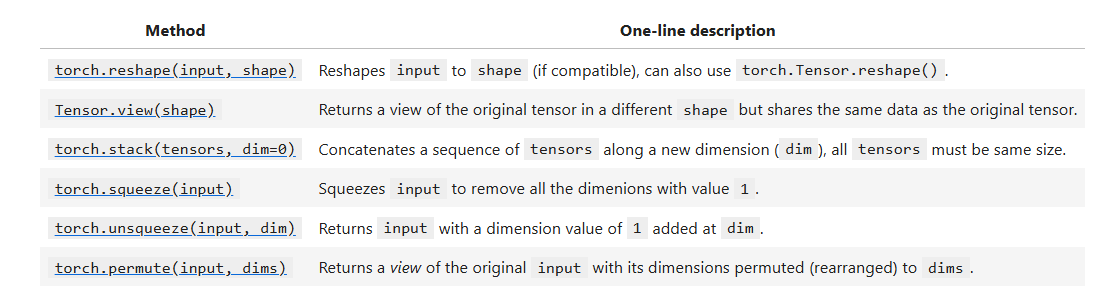

In [ ]:
import torch
x = torch.arange(1. , 10.)
x, x.shape


(tensor([1., 2., 3., 4., 5., 6., 7., 8., 9.]), torch.Size([9]))

In [ ]:
x_reshaped = x.reshape(1,9)
x_reshaped, x_reshaped.shape
# The first number is the numberoff tensor,
# The second is the number of values in a tensor
# Can squeeze 9 elements into 7.
# In summary, the prdocut of the 2 arguments passed must be the number of values.

(tensor([[1., 2., 3., 4., 5., 6., 7., 8., 9.]]), torch.Size([1, 9]))

In [ ]:
 z= x.view(1,9)
 z, z.shape

(tensor([[1., 2., 3., 4., 5., 6., 7., 8., 9.]]), torch.Size([1, 9]))

In [ ]:
x_stacked = torch.stack([x,x,x,x], dim=0)
x_stacked

tensor([[1., 2., 3., 4., 5., 6., 7., 8., 9.],
        [1., 2., 3., 4., 5., 6., 7., 8., 9.],
        [1., 2., 3., 4., 5., 6., 7., 8., 9.],
        [1., 2., 3., 4., 5., 6., 7., 8., 9.]])

In [ ]:
# torch.squueze() => removes all single dimensions
x_reshaped.shape

torch.Size([1, 9])

In [ ]:
x_reshaped.squeeze()

tensor([1., 2., 3., 4., 5., 6., 7., 8., 9.])

In [ ]:
x_reshaped.squeeze().shape
# Takes away all 1 dimensions.

torch.Size([9])

In [ ]:
print(f"Previous tensor: {x_reshaped}")
print(f"Previous shape: {x_reshaped.shape}")

# Remove extra dimension from x_reshaped
x_squeezed = x_reshaped.squeeze()
print(f"\nNew tensor: {x_squeezed}")
print(f"New shape: {x_squeezed.shape}")

In [ ]:

print(f"Previous tensor: {x_squeezed}")
print(f"Previous shape: {x_squeezed.shape}")

## Add an extra dimension with unsqueeze
x_unsqueezed = x_squeezed.unsqueeze(dim=0)
print(f"\nNew tensor: {x_unsqueezed}")
print(f"New shape: {x_unsqueezed.shape}")

In [ ]:
# torch.permute - rearrange the dimensions of a target tensor in a specifiied order
x_original = torch.rand(size=(224,224,3)) # [height, width, color_channels]

# Permute the original
x_permuted = x_original.permute(2,0,1) # shifts axis 0->1, 1->2, 2->0
print(f"Previous shape: {x_original.shape}")
print(f"New shape: {x_permuted.shape}")

NameError: name 'torch' is not defined

In [ ]:
import torch
x= torch.arange(1,10).reshape(1,3,3)
x, x.shape

In [ ]:
x[0][0]

In [ ]:
x[0][0][0]
x[0,0,0]

In [ ]:
x[:, 0, 0]
# Same as x[0][0]


In [ ]:
import torch
import numpy as np
array  =  np.arange(1.0, 8.0)
tensor = torch.from_numpy(array)
array, tensor

In [ ]:
array = array + 1
array

In [ ]:
array, tensor

In [ ]:
tensor = torch.ones(7)
numpy_tensor = tensor.numpy()
tensor, numpy_tensor

In [ ]:
numpy_tensor.dtype

In [ ]:
tensor = tensor + 1
tensor

# Reproducability: trying to take random out of random

-  In short, a nueraul network learns like this: random num => tensor operations
-  => update random numbers => try to match data => random num, again and agian
-  To reduce  the randomness in neural network and pytroch comes the concept of a random seed.
-  Essentially what the random seed does is "flavour" the randomness.

In [ ]:
torch.rand(5,6)

In [ ]:
random_tensor_a = torch.rand(3,4)
random_tensor_b = torch.rand(3,4)
print(random_tensor_a)
print(random_tensor_b)
print(random_tensor_a == random_tensor_b)

In [ ]:
random_seed = 42
torch.manual_seed(random_seed)
random_tensor_c = torch.rand(3,4)

torch.manual_seed(random_seed)
random_tensor_d = torch.rand(3,4)

print(random_tensor_c)
print(random_tensor_d)
print(random_tensor_c == random_tensor_d)

tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.6009, 0.2566, 0.7936],
        [0.9408, 0.1332, 0.9346, 0.5936]])
tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.6009, 0.2566, 0.7936],
        [0.9408, 0.1332, 0.9346, 0.5936]])
tensor([[True, True, True, True],
        [True, True, True, True],
        [True, True, True, True]])


# Controlling GPUs: faster computations. Thanks to Nvidia hardware and CUDA.
-  Options- google colab, use your own GPU, cloud computing

In [ ]:
!nvidia-smi

Wed Oct  8 17:44:43 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P0             30W /   70W |     120MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
torch.cuda.is_available()

True

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
torch.cuda.device_count()

1

Putting tensors and model on the GPU
This is simply faster.

In [ ]:
tensor = torch.tensor([1,2,3])
print(tensor, tensor.device)

tensor([1, 2, 3]) cpu


In [ ]:
# Move tensor to GPU
tensor_on_gpu = tensor.to(device)
tensor_on_gpu

tensor([1, 2, 3], device='cuda:0')

In [ ]:
# If tensor is on GPU. can't transfor it to NumPy
tensor_back_on_gpu = tensor_on_gpu.cpu().numpy()
tensor_back_on_gpu

array([1, 2, 3])

In [ ]:
tensor = tensor.to(device)
tensor

tensor([1, 2, 3], device='cuda:0')

In [ ]:
tensor = tensor.cpu().numpy()
tensor

array([1, 2, 3])

## These were the Pytorch fundamentals which are the building blocks for more complex models.
The series continues with 01_pytorch, avaliable in the same GitHub repo.